## **X11**: TT - From the Diagnosis to a Quantum Task
* October 23°, 2026
#### ESCOM - IPN:

#### *B.S. in Computer Science*
> Miguel Alexander Sanchez Garcia

#### **0° Introduction**

H-048 measured two ends.
- **The real labels.** With benign and malignant, no quantum kernel beats the classical ones.
- **Designed labels.** On the same lesions, labels designed with the procedure of Huang et al. (Supplementary section 7) follow the geometry of the quantum kernel, and with them the projected quantum kernel wins by a wide margin (0.998 against 0.800 in masses).

This notebook walks the path between the two (D-044). Each lesion keeps its real label or takes the designed one. The weight $\alpha$ is the fraction of lesions whose label follows the quantum geometry:
- $\alpha=0$ is the real diagnosis;
- $\alpha=1$ is the designed task.

**Three questions.**
1. **How much quantum structure does a task need before a quantum kernel wins?** The answer is the threshold $\alpha^*$: the smallest $\alpha$ at which the quantum side beats the best classical side with a patient-bootstrap interval entirely above 0.
2. **Where is the real diagnosis on that path?** At $\alpha=0$, by construction. The question is how far it is from $\alpha^*$.
3. **Why do some quantum kernels never win, whatever the labels?** Huang et al. bound the advantage of any labelling by the geometric difference $g$.

**The theory, briefly.** For a kernel $K$ and labels $y$, Huang et al. measure how hard the labels are for that kernel with $s_K(y)=y^\top K^{-1}y$: the larger $s$, the more data the kernel needs to learn them. The prediction error of a kernel method scales as $\sqrt{s/N}$.
- **The quantity that matters is the ratio $s_C/s_Q$.** If it is large, the labels are easy for the quantum kernel and hard for the classical one.
- **That ratio is bounded:** $s_C/s_Q \le g^2$. The proof is one line: write $y=\sqrt{K_Q}\,w$, then $s_C = w^\top\sqrt{K_Q}A\sqrt{K_Q}\,w \le \|\sqrt{K_Q}A\sqrt{K_Q}\|\,w^\top w = g^2 s_Q$, where $A$ is the regularized inverse of $K_C$.
- **The designed labels are the ones that reach the bound.** They are built from the top eigenvector of $\sqrt{K_Q}A\sqrt{K_Q}$.

A kernel with small $g$ cannot have a large advantage on **any** labelling. A kernel with large $g$ can, but only on labels that follow its geometry.

**What this notebook is not.** The intermediate labels are artificial: they mix the diagnosis with a property of the quantum kernel. This is a measuring device, not a clinical task, and the official test split is not used.

#### **0°a The protocol (D-044)**

| Element | Choice | Why |
|---|---|---|
| Inputs | The 12 angles of M4, whole training split | The same data as H-048 |
| Quantum kernels | ZZ full (C4), ZZ linear, projected ZZ full (median bandwidth) | The three of H-048: two with small $g$ and one with large $g$ |
| Designed labels | Exactly those of X6 §5: closest classical kernel of `X6_geometria.csv`, the smallest $\lambda$ whose training bound is $\le 0.002$, $y=\sqrt{K_Q}v$ split at the median | Reproducible; checked against `X6_etiquetas_construidas.csv` |
| Sign | The eigenvector sign is arbitrary; it is set so that the designed labels agree with the real ones on at least half of the lesions | Needed only for the mixture; the AUC of the pure tasks does not depend on it |
| Mixture | One uniform number $u$ per lesion and seed (5 seeds); the lesion takes the designed label if $u<\alpha$ | The masks are nested: raising $\alpha$ only adds lesions |
| Quantum contender | SVM on the quantum kernel, $C=1$ | No hyperparameter to tune |
| Classical contender | Nested search (3 inner folds by patient) among linear, polynomial (degree 2 and 3) and 9 Gaussian SVMs, and XGBoost with 4 configurations | The classical side gets a search and the quantum side does not: an advantage that survives is conservative |
| Evaluation | Cross-validation with the 5 frozen folds of M4; patient bootstrap of the training lesions, paired, averaged over the 5 masks | As in X6 |
| Threshold $\alpha^*$ | The smallest $\alpha$ whose interval for quantum − classical lies entirely above 0 | Fixed before running |

#### **1° Setup**

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
import sklearn
import xgboost
from joblib import Parallel, delayed
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.linalg import eigh
from scipy.stats import rankdata
from sklearn.metrics import pairwise_distances, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
QUICK = os.environ.get('X11_QUICK') == '1'          # smoke test: 3 values of alpha, 1 mask, writes to /tmp only
SEED, N_FOLDS, N_INNER, K = 42, 5, 3, 12
N_BOOT = 50 if QUICK else 2000
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
ALPHAS = np.array([0.0, 0.5, 1.0]) if QUICK else np.round(np.linspace(0, 1, 11), 1)
MASK_SEEDS = [0] if QUICK else [0, 1, 2, 3, 4]
MULTIPLIERS = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]          # the Gaussian grid of Huang et al., as in X6
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2, 0.025, 0.05, 0.1]
XGB_GRID = [{'n_estimators': n, 'max_depth': d, 'learning_rate': 0.1} for n in [100, 300] for d in [2, 4]]
QUANTUM = ['ZZ full (C4)', 'ZZ linear', 'Projected (ZZ full)']
GEO_NAME = {'ZZ full (C4)': 'ZZ full', 'ZZ linear': 'ZZ linear', 'Projected (ZZ full)': 'Projected (ZZ full), median bandwidth'}
X_COLUMNS = [f'x_{i:02d}' for i in range(1, K + 1)]
ROOT = Path('/Users/alexander_san/TT')
M4_DIR, X6_DIR = ROOT / 'Data/processed/m4', ROOT / 'Code/results'
RESULTS_DIR, FIG_DIR = (Path('/tmp/x11_quick'),) * 2 if QUICK else (ROOT / 'Code/results', ROOT / 'Docs/Figures')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_MAPS = {'ZZ full': zz_feature_map(K, reps=1, entanglement='full'), 'ZZ linear': zz_feature_map(K, reps=1, entanglement='linear')}
COLORS = {'quantum': '#eb6834', 'classical': '#2a78d6', 'ZZ full (C4)': '#eb6834', 'ZZ linear': '#1baf7a', 'Projected (ZZ full)': '#7a4fc9'}
INK = '#3d3d3a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})
LOG = Path('/tmp/x11_run.log')


def log(msg):
    line = f"{time.strftime('%H:%M:%S')} {msg}"
    print(line, flush=True)
    with LOG.open('a') as fh:
        fh.write(line + '\n')


data = {}
for ft in FINDINGS:
    d4 = pd.read_parquet(M4_DIR / f'x_{ft}.parquet')
    tr = d4[d4.split == 'train'].reset_index(drop=True)
    data[ft] = {'X': tr[X_COLUMNS].to_numpy(float), 'y': tr.label.to_numpy(int), 'folds': tr.fold.to_numpy(int),
                'patients': tr.patient_id.to_numpy()}
log(f'X11 start (QUICK={QUICK}) | qiskit {qiskit.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | numpy {np.__version__}')

09:46:13 X11 start (QUICK=False) | qiskit 2.3.0 | scikit-learn 1.7.2 | xgboost 3.2.0 | numpy 2.2.6


**a.** Functions copied verbatim from X6 (kernels, square roots, the ratio $s_C/s_Q$), so that $\alpha=1$ reproduces H-048

In [2]:
checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})


def sym(a):
    return (a + a.T) / 2


def normalize_trace(k):
    return k * len(k) / np.trace(k)


def psd_sqrt(k):
    t, v = eigh(sym(k))
    return (v * np.sqrt(np.clip(t, 0, None))) @ v.T


def top_eigenvalue(m):
    return float(eigh(sym(m), eigvals_only=True)[-1])


def states(fm, X):
    return np.array([Statevector(fm.assign_parameters(dict(zip(fm.parameters, x)))).data for x in X])


def one_qubit_paulis(S, n=K):
    out = np.empty((len(S), 3 * n))
    for k in range(n):
        T = np.moveaxis(S.reshape((len(S),) + (2,) * n), 1 + (n - 1 - k), 1).reshape(len(S), 2, -1)
        a0, a1 = T[:, 0, :], T[:, 1, :]
        z = (np.conj(a0) * a1).sum(1)
        out[:, 3 * k], out[:, 3 * k + 1] = 2 * z.real, 2 * z.imag
        out[:, 3 * k + 2] = (np.abs(a0) ** 2).sum(1) - (np.abs(a1) ** 2).sum(1)
    return out


def gaussian(F, gamma):
    return np.exp(-gamma * pairwise_distances(F, metric='sqeuclidean'))


def classical_suite(x, multipliers):
    n_feat, var = x.shape[1], x.var()
    sq = ((x[:, None, :] - x[None, :, :]) ** 2).sum(-1)
    xc = x - x.mean(0)
    suite = {'linear': normalize_trace(xc @ xc.T)}
    for m in multipliers:
        suite[f'gaussian {m:g}'] = np.exp(-(m / (n_feat * var)) * sq)
    return suite


def ratio_sc_sq(y, kq, kc, lam):
    # s_C (regularized) over s_Q = y^T K_Q^-1 y, as in X6
    t, v = eigh(sym(kc))
    t = np.clip(t, 0, None)
    a = (v * (t / (t + lam) ** 2)) @ v.T
    return (y @ a @ y) / (y @ np.linalg.solve(kq + 1e-10 * np.eye(len(kq)), y))


def svm_cv(Kmat, y, folds, C=1.0):
    out = []
    for f in range(N_FOLDS):
        a, b = folds != f, folds == f
        m = SVC(kernel='precomputed', C=C, class_weight='balanced').fit(Kmat[np.ix_(a, a)], y[a])
        out.append(roc_auc_score(y[b], m.decision_function(Kmat[np.ix_(b, a)])))
    return np.mean(out)


def fast_auc(y, p):
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))

**b.** Kernels on the whole training split: the three quantum kernels and the classical candidates. The polynomial kernels and the Gaussian grid follow the candidate list of X6 (§2).

In [3]:
t0 = time.perf_counter()
for ft in FINDINGS:
    d = data[ft]
    X = d['X']
    S_full, S_lin = states(FEATURE_MAPS['ZZ full'], X), states(FEATURE_MAPS['ZZ linear'], X)
    F = one_qubit_paulis(S_full)
    keep = F.std(0) > 1e-12
    sq = pairwise_distances(F[:, keep], metric='sqeuclidean')
    d['quantum'] = {'ZZ full (C4)': np.abs(S_full.conj() @ S_full.T) ** 2, 'ZZ linear': np.abs(S_lin.conj() @ S_lin.T) ** 2,
                    'Projected (ZZ full)': np.exp(-sq / (2 * np.median(sq[np.triu_indices(len(sq), 1)])))}
    d['suite'] = classical_suite(X, MULTIPLIERS)
    xc = X - X.mean(0)
    cands = {'linear': d['suite']['linear']}
    for deg in [2, 3]:
        Kp = (1.0 + (xc @ xc.T) / K) ** deg
        cands[f'polynomial {deg}'] = Kp / np.sqrt(np.outer(np.diag(Kp), np.diag(Kp)))
    for m in MULTIPLIERS:
        cands[f'gaussian {m:g}'] = d['suite'][f'gaussian {m:g}']
    d['classical'] = cands
    trn = np.arange(len(d['y']))
    d['inner'] = {}
    for f in range(N_FOLDS):
        a = np.flatnonzero(d['folds'] != f)
        sgkf = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=SEED)
        d['inner'][f] = [(a[i], a[j]) for i, j in sgkf.split(a, d['y'][a], d['patients'][a])]
    leak = sum(len(set(d['patients'][a]) & set(d['patients'][b])) for s in d['inner'].values() for a, b in s)
    check(f'{ft}: no patient on both sides of an inner split', leak, leak == 0)
    uniq, inv = np.unique(d['patients'], return_inverse=True)
    members = [np.flatnonzero(inv == i) for i in range(len(uniq))]
    rng = np.random.default_rng(SEED)
    d['boot'] = [np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]) for _ in range(N_BOOT)]
    log(f'{ft}: kernels for {len(d["y"])} lesions in {time.perf_counter() - t0:.0f} s')

09:46:25 mass: kernels for 1318 lesions in 12 s


09:46:40 calcification: kernels for 1546 lesions in 27 s


#### **2° The designed labels**

**a.** For each quantum kernel the procedure of X6 §5, exactly:
1. $K_C$ is the closest classical kernel on the 200 lesions of Module 6 (`X6_geometria.csv`).
2. $\lambda$ is the smallest value of the grid whose training bound $\lambda^2\|\sqrt{K_Q}(K_C+\lambda I)^{-2}\sqrt{K_Q}\|$ is at most 0.002.
3. $v$ is the top eigenvector of $\sqrt{K_Q}\sqrt{K_C}(K_C+\lambda I)^{-2}\sqrt{K_C}\sqrt{K_Q}$, and $y=\sqrt{K_Q}v$ is split at its median.

Every pure task must reproduce `X6_etiquetas_construidas.csv`. The table also shows how much the designed labels agree with the diagnosis: about 50 % means the two are unrelated.

In [4]:
geo = pd.read_csv(X6_DIR / 'X6_geometria.csv')
x6 = pd.read_csv(X6_DIR / 'X6_etiquetas_construidas.csv').set_index(['finding_type', 'quantum_kernel'])
design_rows = []
for ft in FINDINGS:
    d = data[ft]
    d['design'] = {}
    for q in QUANTUM:
        row = geo[(geo.finding_type == ft) & (geo.encoding == GEO_NAME[q])].iloc[0]
        kname = row.closest_classical if isinstance(row.closest_classical, str) else 'gaussian 64'
        kq, kc = d['quantum'][q], d['suite'][kname]
        sq_root = psd_sqrt(kq)
        t, v = eigh(sym(kc))
        t = np.clip(t, 0, None)
        for lam in LAMBDAS:
            tra = sq_root @ ((v * (1 / (t + lam) ** 2)) @ v.T) @ sq_root
            if lam ** 2 * top_eigenvalue(tra) <= 0.002:
                break
        gen = sq_root @ ((v * (t / (t + lam) ** 2)) @ v.T) @ sq_root
        w, vecs = eigh(sym(gen))
        g_built = np.sqrt(w[-1])
        y_cont = sq_root @ vecs[:, -1]
        y_eng = (y_cont > np.median(y_cont)).astype(int)
        q_auc, c_auc = svm_cv(kq, y_eng, d['folds']), max(svm_cv(kk, y_eng, d['folds']) for kk in d['suite'].values())
        q_real, c_real = svm_cv(kq, d['y'], d['folds']), max(svm_cv(kk, d['y'], d['folds']) for kk in d['suite'].values())
        ref = x6.loc[(ft, q)]
        err = max(abs(q_auc - ref.built_qsvm_auc), abs(c_auc - ref.built_best_classical_auc), abs(g_built - ref.g_built),
                  abs(q_real - ref.real_qsvm_auc), abs(c_real - ref.real_best_classical_auc))
        check(f'{ft}, {q}: designed task and real labels reproduce X6 (AUC, g)', err, err < 1e-9)
        agree = (y_eng == d['y']).mean()
        if agree < 0.5:                                      # orient the arbitrary eigenvector sign
            y_eng, agree = 1 - y_eng, 1 - agree
        d['design'][q] = {'y': y_eng, 'kc': kc, 'lam': lam, 'g2': g_built ** 2}
        design_rows.append({'finding_type': ft, 'quantum_kernel': q, 'closest_classical': kname, 'lambda': lam, 'g_built': g_built,
                            'malignant_share_designed': y_eng.mean(), 'agreement_with_diagnosis': agree,
                            'qsvm_auc_designed': q_auc, 'best_classical_auc_designed': c_auc})
design = pd.DataFrame(design_rows)
for _, r in design.iterrows():
    check(f'{r.finding_type}, {r.quantum_kernel}: the designed labels are balanced', r.malignant_share_designed,
          abs(r.malignant_share_designed - 0.5) < 0.005)
display(design.round(4))

,finding_type,quantum_kernel,closest_classical,lambda,g_built,malignant_share_designed,agreement_with_diagnosis,qsvm_auc_designed,best_classical_auc_designed
0,mass,ZZ full (C4),gaussian 64,0.0,2.9980,0.5,0.5114,0.7297,0.7120
1,mass,ZZ linear,gaussian 64,0.0,2.5308,0.5,0.5615,0.9083,0.8472
2,mass,Projected (ZZ full),gaussian 16,0.0,18.2578,0.5,0.5387,0.9981,0.7999
3,calcification,ZZ full (C4),gaussian 64,0.0,3.3691,0.5,0.5013,0.8292,0.8069
4,calcification,ZZ linear,gaussian 64,0.0,1.7992,0.5,0.5142,0.7305,0.5870
5,calcification,Projected (ZZ full),gaussian 8,0.0,40.2189,0.5,0.5168,0.9941,0.8245


**b.** The mixtures. For each seed, each lesion draws one uniform number $u$, the same for every $\alpha$. The lesion takes the designed label when $u<\alpha$. So $\alpha=0$ is exactly the diagnosis, $\alpha=1$ exactly the designed task, and raising $\alpha$ only changes more lesions.

In [5]:
label_sets, nested_ok = {}, True     # (ft, q, alpha, seed) -> labels
for ft in FINDINGS:
    d = data[ft]
    n = len(d['y'])
    for s in MASK_SEEDS:
        u = np.random.default_rng(SEED + s).random(n)
        for q in QUANTUM:
            prev = np.zeros(n, bool)
            for a in ALPHAS:
                mask = u < a
                label_sets[(ft, q, a, s)] = np.where(mask, d['design'][q]['y'], d['y'])
                nested_ok &= bool((prev <= mask).all())
                prev = mask
    for q in QUANTUM:
        same0 = all((label_sets[(ft, q, 0.0, s)] == d['y']).all() for s in MASK_SEEDS)
        same1 = all((label_sets[(ft, q, 1.0, s)] == d['design'][q]['y']).all() for s in MASK_SEEDS)
        check(f'{ft}, {q}: alpha = 0 is the diagnosis and alpha = 1 the designed task', 0, same0 and same1)
check('masks are nested in alpha: raising alpha only changes more lesions', 0, nested_ok)
log(f'{len(label_sets)} label sets')

09:47:01 330 label sets


#### **3° Quantum against classical along the path**

**a.** For every label set, one worker computes:
- the cross-validated scores of the three quantum SVMs, with no tuning;
- every classical candidate (12 SVMs and 4 XGBoost configurations) with its inner AUC;
- the nested choice of the classical side in each outer fold;
- the patient bootstrap of the mean fold AUC.

The bootstrap resamples are the same for every label set of a subset, so the differences are paired. The real labels are evaluated once and shared by every kernel and seed.

In [6]:
def sample_weights(y):
    n, n1 = len(y), int(y.sum())
    return np.where(y == 1, n / (2 * n1), n / (2 * (n - n1)))


def boot_dist(y, scores, folds, samples):
    return np.array([np.mean([fast_auc(y[s[folds[s] == f]], scores[s[folds[s] == f]]) for f in range(N_FOLDS)]) for s in samples])


def evaluate(y, quantum, classical, X, folds, inner, samples):
    out = {}
    for q, kq in quantum.items():                                # quantum side: fixed kernel, C = 1
        s_all = np.empty(len(y))
        for f in range(N_FOLDS):
            a, b = folds != f, folds == f
            m = SVC(kernel='precomputed', C=1.0, class_weight='balanced').fit(kq[np.ix_(a, a)], y[a])
            s_all[b] = m.decision_function(kq[np.ix_(b, a)])
        out[q] = s_all
    cand_inner, cand_outer = {}, {}
    for name, kk in classical.items():                           # classical SVMs
        cand_inner[name], cand_outer[name] = [], np.empty(len(y))
        for f in range(N_FOLDS):
            vals = []
            for ia, ib in inner[f]:
                m = SVC(kernel='precomputed', C=1.0, class_weight='balanced').fit(kk[np.ix_(ia, ia)], y[ia])
                vals.append(roc_auc_score(y[ib], m.decision_function(kk[np.ix_(ib, ia)])))
            cand_inner[name].append(np.mean(vals))
            a, b = folds != f, folds == f
            m = SVC(kernel='precomputed', C=1.0, class_weight='balanced').fit(kk[np.ix_(a, a)], y[a])
            cand_outer[name][b] = m.decision_function(kk[np.ix_(b, a)])
    for gi, params in enumerate(XGB_GRID):                       # classical XGBoost
        name = f"xgboost {params['n_estimators']}x{params['max_depth']}"
        make = lambda: XGBClassifier(**params, subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=1,
                                     random_state=SEED, eval_metric='logloss')
        cand_inner[name], cand_outer[name] = [], np.empty(len(y))
        for f in range(N_FOLDS):
            vals = []
            for ia, ib in inner[f]:
                m = make().fit(X[ia], y[ia], sample_weight=sample_weights(y[ia]))
                vals.append(roc_auc_score(y[ib], m.predict_proba(X[ib])[:, 1]))
            cand_inner[name].append(np.mean(vals))
            a, b = folds != f, folds == f
            cand_outer[name][b] = make().fit(X[a], y[a], sample_weight=sample_weights(y[a])).predict_proba(X[b])[:, 1]
    names = list(cand_inner)
    chosen, s_cl = [], np.empty(len(y))
    for f in range(N_FOLDS):                                     # nested choice: argmax of the inner AUC, ties to the first
        best = names[int(np.argmax([cand_inner[nm][f] for nm in names]))]
        chosen.append(best)
        s_cl[folds == f] = cand_outer[best][folds == f]
    out['classical'] = s_cl
    res = {'chosen': chosen}
    for key, sc in out.items():
        res[f'{key}_auc'] = np.mean([roc_auc_score(y[folds == f], sc[folds == f]) for f in range(N_FOLDS)])
        res[f'{key}_dist'] = boot_dist(y, sc, folds, samples)
    return res


unique = {}
for key, y in label_sets.items():
    ft = key[0]
    h = (ft, y.tobytes())
    unique.setdefault(h, (ft, y))
log(f'{len(unique)} distinct label sets to evaluate')
t0 = time.perf_counter()
results = {}
for ft in FINDINGS:
    d = data[ft]
    todo = [(h, y) for h, (f2, y) in unique.items() if f2 == ft]
    out = Parallel(n_jobs=8, batch_size=1)(delayed(evaluate)(y, d['quantum'], d['classical'], d['X'], d['folds'], d['inner'], d['boot'])
                                           for _, y in todo)
    results.update({h: r for (h, _), r in zip(todo, out)})
    log(f'{ft}: {len(todo)} label sets evaluated, {(time.perf_counter() - t0) / 60:.1f} min so far')

09:47:01 278 distinct label sets to evaluate


09:50:30 mass: 139 label sets evaluated, 3.5 min so far


09:54:47 calcification: 139 label sets evaluated, 7.8 min so far


**b.** Per $\alpha$: the AUC of each side, averaged over the five masks; the paired difference quantum − classical with its patient-bootstrap interval (the bootstrap distributions of the five masks are averaged); and the ratio $s_C/s_Q$ of the mixed labels with its ceiling $g^2$.

In [7]:
rows, path_rows = [], []
for (ft, q, a, s), y in label_sets.items():
    r = results[(ft, y.tobytes())]
    dz = data[ft]['design'][q]
    ratio = ratio_sc_sq(2.0 * y - 1, data[ft]['quantum'][q], dz['kc'], dz['lam'])
    rows.append({'finding_type': ft, 'quantum_kernel': q, 'alpha': a, 'seed': s, 'quantum_auc': r[f'{q}_auc'],
                 'classical_auc': r['classical_auc'], 'difference': r[f'{q}_auc'] - r['classical_auc'],
                 'ratio_sc_sq': ratio, 'g2': dz['g2'], 'classical_chosen': '; '.join(r['chosen'])})
per_seed = pd.DataFrame(rows)
for (ft, q, a), part in per_seed.groupby(['finding_type', 'quantum_kernel', 'alpha']):
    dists = [results[(ft, label_sets[(ft, q, a, s)].tobytes())] for s in MASK_SEEDS]
    dd = np.mean([r[f'{q}_dist'] - r['classical_dist'] for r in dists], axis=0)
    path_rows.append({'finding_type': ft, 'quantum_kernel': q, 'alpha': a, 'quantum_auc': part.quantum_auc.mean(),
                      'classical_auc': part.classical_auc.mean(), 'difference': part.difference.mean(),
                      'ci_low': np.percentile(dd, 2.5), 'ci_high': np.percentile(dd, 97.5),
                      'quantum_auc_range': part.quantum_auc.max() - part.quantum_auc.min(),
                      'ratio_sc_sq': part.ratio_sc_sq.mean(), 'g2': part.g2.iloc[0]})
path = pd.DataFrame(path_rows)
path['quantum_wins'] = path.ci_low > 0
path['classical_wins'] = path.ci_high < 0
threshold = (path[path.quantum_wins].groupby(['finding_type', 'quantum_kernel']).alpha.min()
             .reindex(pd.MultiIndex.from_product([FINDINGS, QUANTUM], names=['finding_type', 'quantum_kernel'])).rename('alpha_star'))
display(path.pivot_table(index=['finding_type', 'quantum_kernel'], columns='alpha', values='difference').round(3))
display(threshold.to_frame())
excess = (per_seed.ratio_sc_sq - per_seed.g2).max()
check('s_C / s_Q never exceeds g^2 (the bound of Huang et al.)', excess, excess <= 1e-6)

alpha                                0.0    0.1    0.2    0.3    0.4    0.5  \
finding_type  quantum_kernel                                                  
calcification Projected (ZZ full) -0.096 -0.090 -0.055 -0.019  0.009  0.031   
              ZZ full (C4)        -0.012 -0.002  0.003  0.002  0.005  0.003   
              ZZ linear           -0.050 -0.035 -0.025 -0.013 -0.010  0.000   
mass          Projected (ZZ full) -0.111 -0.065 -0.030  0.003  0.043  0.081   
              ZZ full (C4)        -0.020 -0.015 -0.006 -0.002 -0.000  0.004   
              ZZ linear           -0.040 -0.031 -0.024 -0.015  0.006  0.023   

alpha                                0.6    0.7    0.8    0.9    1.0  
finding_type  quantum_kernel                                          
calcification Projected (ZZ full)  0.043  0.058  0.071  0.089  0.118  
              ZZ full (C4)         0.003  0.012  0.018  0.026  0.024  
              ZZ linear            0.023  0.048  0.084  0.121  0.163  
mass          Projected (ZZ full)  0.095  0.099  0.114  0.137  0.141  
              ZZ full (C4)         0.011  0.016  0.021  0.033  0.035  
              ZZ linear            0.025  0.027  0.031  0.045  0.042

alpha_star
finding_type  quantum_kernel                 
mass          ZZ full (C4)                0.6
              ZZ linear                   0.5
              Projected (ZZ full)         0.4
calcification ZZ full (C4)                0.7
              ZZ linear                   0.6
              Projected (ZZ full)         0.5

**c.** Figures: the two sides along the path, the difference with its interval, and the ratio $s_C/s_Q$ against its ceiling $g^2$

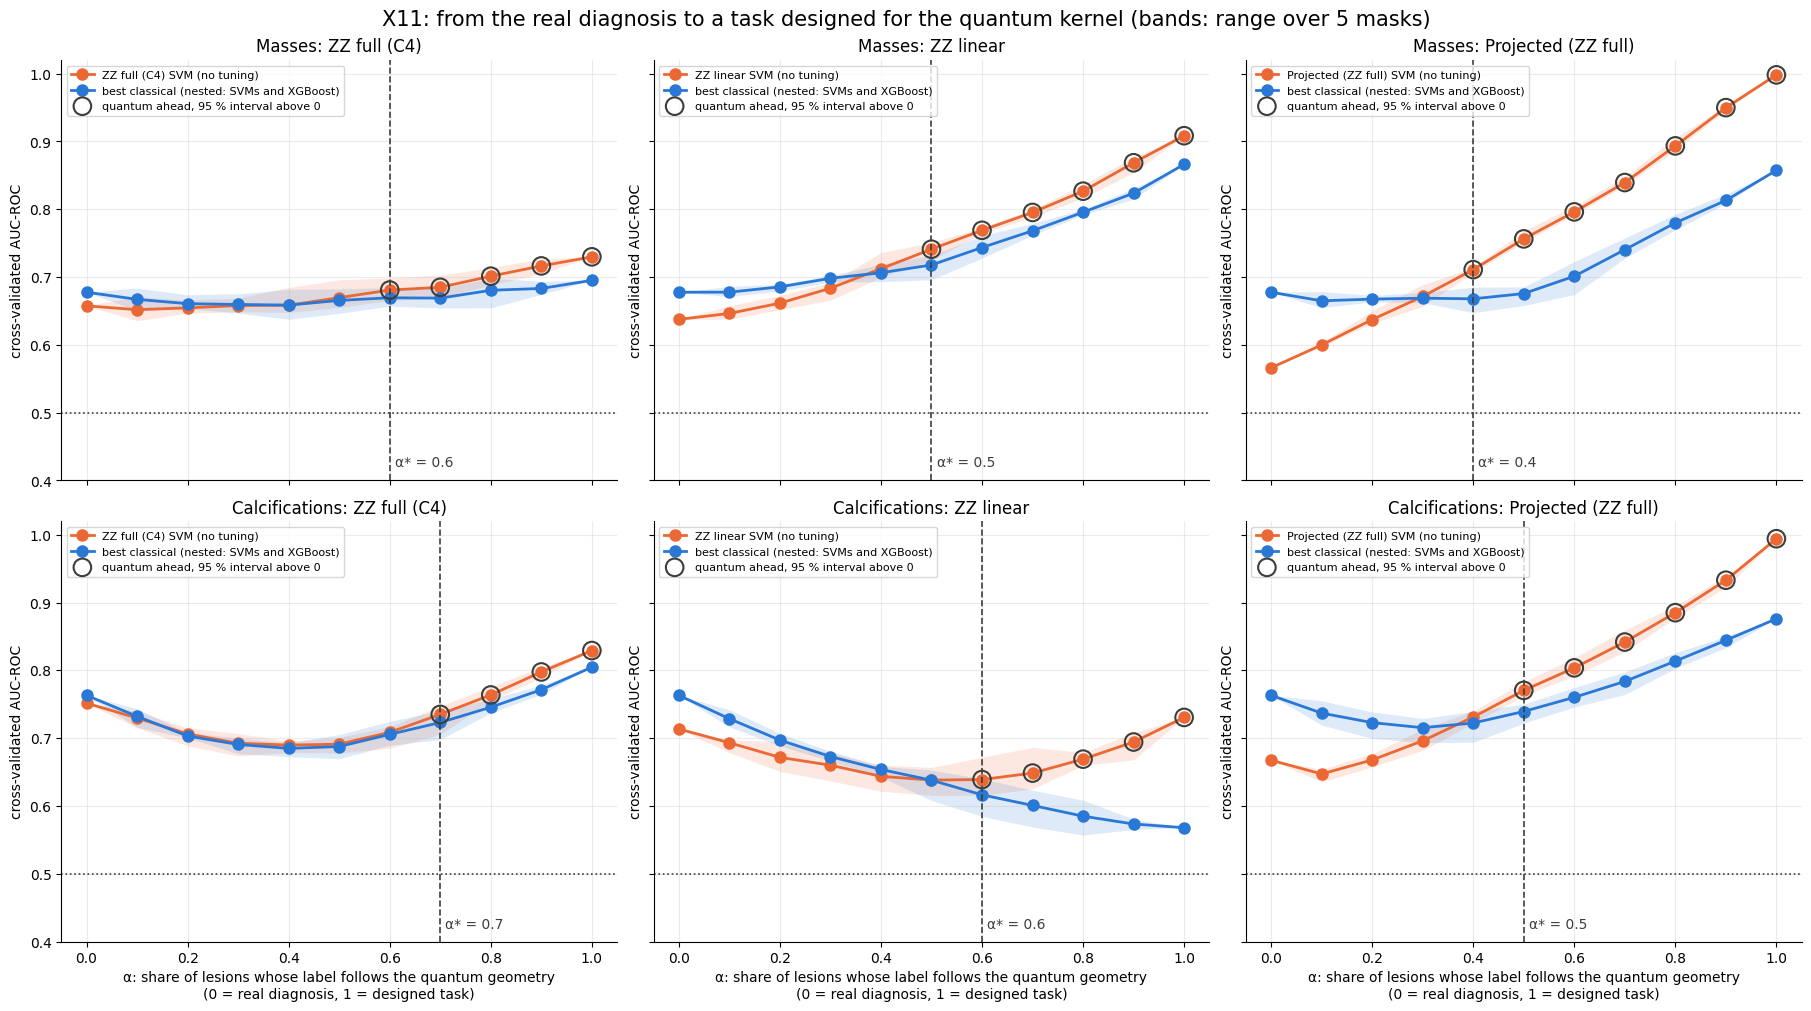

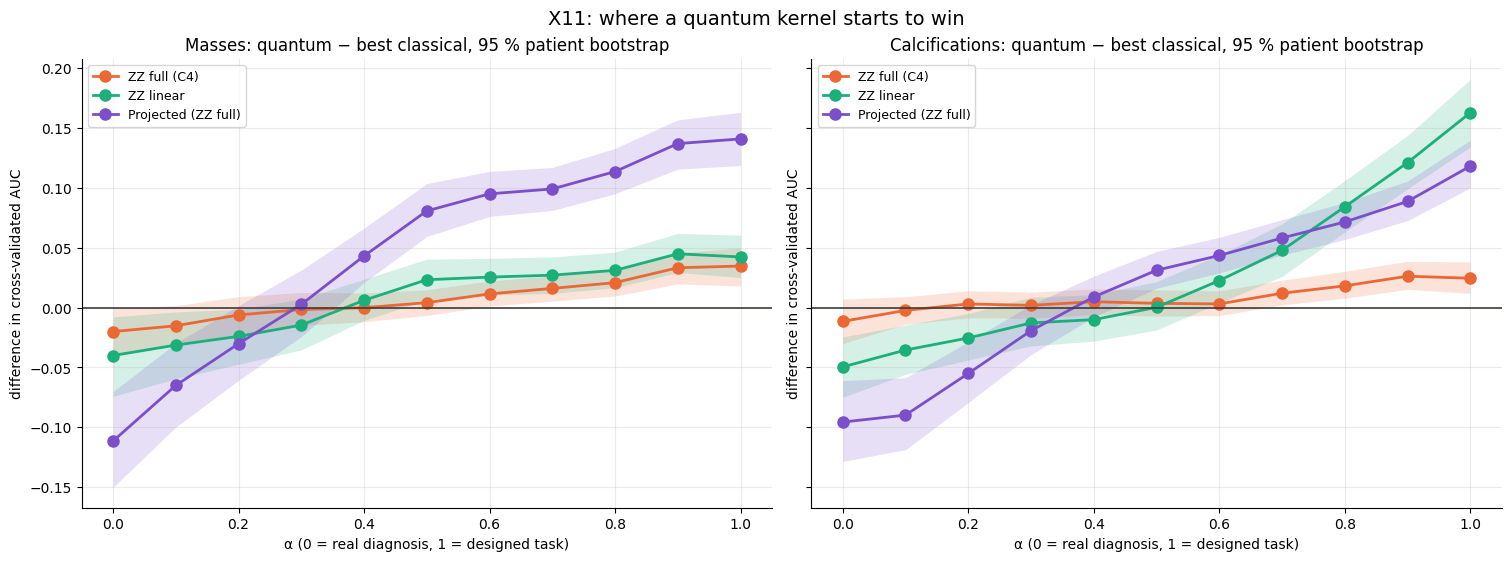

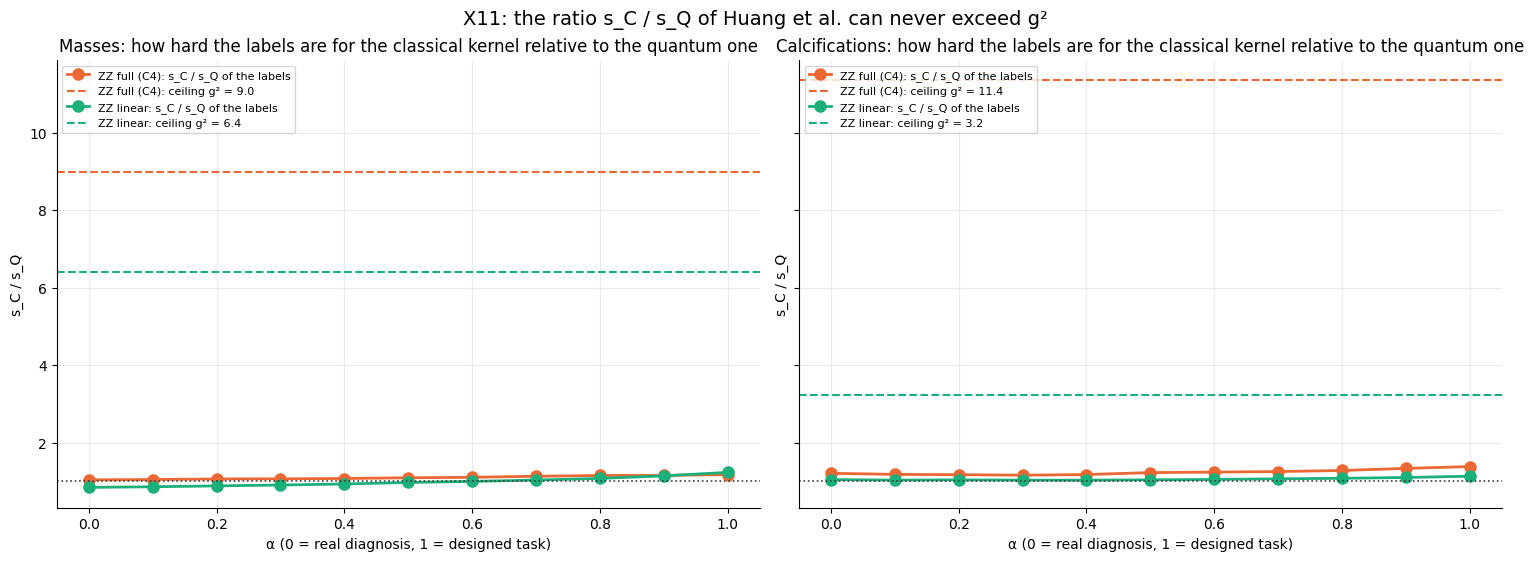

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True, sharex=True, sharey='row')
for row, ft in zip(axes, FINDINGS):
    for ax, q in zip(row, QUANTUM):
        p = path[(path.finding_type == ft) & (path.quantum_kernel == q)].sort_values('alpha')
        ps = per_seed[(per_seed.finding_type == ft) & (per_seed.quantum_kernel == q)]
        for side, col in [('quantum', 'quantum_auc'), ('classical', 'classical_auc')]:
            lo, hi = ps.groupby('alpha')[col].min(), ps.groupby('alpha')[col].max()
            ax.fill_between(lo.index, lo, hi, color=COLORS[side], alpha=0.15, lw=0)
            ax.plot(p.alpha, p[col], 'o-', color=COLORS[side],
                    label=f'{q} SVM (no tuning)' if side == 'quantum' else 'best classical (nested: SVMs and XGBoost)')
        win = p[p.quantum_wins]
        ax.scatter(win.alpha, win.quantum_auc, s=160, facecolor='none', edgecolor=INK, lw=1.5, zorder=4,
                   label='quantum ahead, 95 % interval above 0')
        a_star = threshold.loc[(ft, q)]
        if pd.notna(a_star):
            ax.axvline(a_star, color=INK, ls='--', lw=1.2)
            ax.text(a_star + 0.01, 0.42, f'α* = {a_star:.1f}', fontsize=10, color=INK)
        ax.axhline(0.5, color=INK, ls=':', lw=1.2)
        ax.set(title=f'{TITLES[ft]}: {q}', ylabel='cross-validated AUC-ROC', ylim=(0.4, 1.02))
        ax.legend(fontsize=8, loc='upper left')
for ax in axes[-1]:
    ax.set_xlabel('α: share of lesions whose label follows the quantum geometry\n(0 = real diagnosis, 1 = designed task)')
fig.suptitle('X11: from the real diagnosis to a task designed for the quantum kernel (bands: range over 5 masks)', fontsize=15)
fig.savefig(FIG_DIR / 'X11_transition.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True, sharey=True)
for ax, ft in zip(axes, FINDINGS):
    for q in QUANTUM:
        p = path[(path.finding_type == ft) & (path.quantum_kernel == q)].sort_values('alpha')
        ax.fill_between(p.alpha, p.ci_low, p.ci_high, color=COLORS[q], alpha=0.18, lw=0)
        ax.plot(p.alpha, p.difference, 'o-', color=COLORS[q], label=q)
    ax.axhline(0, color=INK, lw=1.2)
    ax.set(title=f'{TITLES[ft]}: quantum − best classical, 95 % patient bootstrap',
           xlabel='α (0 = real diagnosis, 1 = designed task)', ylabel='difference in cross-validated AUC')
    ax.legend(fontsize=9, loc='upper left')
fig.suptitle('X11: where a quantum kernel starts to win', fontsize=14)
fig.savefig(FIG_DIR / 'X11_difference.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True, sharey=True)
for ax, ft in zip(axes, FINDINGS):
    for q in ['ZZ full (C4)', 'ZZ linear']:
        p = path[(path.finding_type == ft) & (path.quantum_kernel == q)].sort_values('alpha')
        ax.plot(p.alpha, p.ratio_sc_sq, 'o-', color=COLORS[q], label=f'{q}: s_C / s_Q of the labels')
        ax.axhline(p.g2.iloc[0], color=COLORS[q], ls='--', lw=1.5, label=f'{q}: ceiling g² = {p.g2.iloc[0]:.1f}')
    ax.axhline(1, color=INK, ls=':', lw=1.2)
    ax.set(title=f'{TITLES[ft]}: how hard the labels are for the classical kernel relative to the quantum one',
           xlabel='α (0 = real diagnosis, 1 = designed task)', ylabel='s_C / s_Q')
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('X11: the ratio s_C / s_Q of Huang et al. can never exceed g²', fontsize=14)
fig.savefig(FIG_DIR / 'X11_ratio.png', dpi=180, bbox_inches='tight')
plt.show()

#### **4° Files and verifications**

In [9]:
y_check = label_sets[('mass', 'ZZ full (C4)', 0.5, 0)]
d = data['mass']
r1 = evaluate(y_check, d['quantum'], d['classical'], d['X'], d['folds'], d['inner'], d['boot'][:20])
r2 = evaluate(y_check, d['quantum'], d['classical'], d['X'], d['folds'], d['inner'], d['boot'][:20])
same = all(np.array_equal(r1[k], r2[k]) for k in r1 if k.endswith('dist')) and r1['chosen'] == r2['chosen']
check('evaluating the same labels twice gives identical results', 0, same)
check('every label set was evaluated', len(results), all((k[0], y.tobytes()) in results for k, y in label_sets.items()))
design.to_csv(RESULTS_DIR / 'X11_etiquetas_disenadas.csv', index=False)
per_seed.to_csv(RESULTS_DIR / 'X11_por_mascara.csv', index=False)
path.to_csv(RESULTS_DIR / 'X11_transicion.csv', index=False)
threshold.reset_index().to_csv(RESULTS_DIR / 'X11_umbral.csv', index=False)
verifications = pd.DataFrame(checks)
verifications.to_csv(RESULTS_DIR / 'X11_verificaciones.csv', index=False)
display(verifications)
log(f'Checks passed: {int(verifications.passed.sum())}/{len(verifications)}')

,check,value,passed
0,mass: no patient on both sides of an inner split,0.000000e+00,True
1,calcification: no patient on both sides of an ...,0.000000e+00,True
2,"mass, ZZ full (C4): designed task and real lab...",2.664535e-15,True
3,"mass, ZZ linear: designed task and real labels...",4.440892e-16,True
4,"mass, Projected (ZZ full): designed task and r...",1.065814e-14,True
5,"calcification, ZZ full (C4): designed task and...",6.883383e-14,True
6,"calcification, ZZ linear: designed task and re...",1.110223e-15,True
7,"calcification, Projected (ZZ full): designed t...",1.073630e-11,True
8,"mass, ZZ full (C4): the designed labels are ba...",5.000000e-01,True
9,"mass, ZZ linear: the designed labels are balanced",5.000000e-01,True


10:01:33 Checks passed: 24/24


In [10]:
print('=' * 100)
print('X11 - FROM THE DIAGNOSIS TO A QUANTUM TASK - SUMMARY (cross-validated AUC, mean of 5 masks)')
print('=' * 100)
for ft in FINDINGS:
    print(f'  {TITLES[ft]}')
    for q in QUANTUM:
        p = path[(path.finding_type == ft) & (path.quantum_kernel == q)].set_index('alpha')
        dz = design[(design.finding_type == ft) & (design.quantum_kernel == q)].iloc[0]
        a_star = threshold.loc[(ft, q)]
        print(f"    {q:20s} g² = {dz.g_built ** 2:6.1f} | alpha = 0: {p.loc[0.0, 'quantum_auc']:.3f} vs {p.loc[0.0, 'classical_auc']:.3f}"
              f" | alpha = 1: {p.loc[1.0, 'quantum_auc']:.3f} vs {p.loc[1.0, 'classical_auc']:.3f}"
              f" | alpha* = {'none' if pd.isna(a_star) else f'{a_star:.1f}'}")
print(f"  Checks passed: {int(verifications.passed.sum())}/{len(verifications)}")
print('=' * 100)

X11 - FROM THE DIAGNOSIS TO A QUANTUM TASK - SUMMARY (cross-validated AUC, mean of 5 masks)
  Masses
    ZZ full (C4)         g² =    9.0 | alpha = 0: 0.657 vs 0.677 | alpha = 1: 0.730 vs 0.695 | alpha* = 0.6
    ZZ linear            g² =    6.4 | alpha = 0: 0.637 vs 0.677 | alpha = 1: 0.908 vs 0.866 | alpha* = 0.5
    Projected (ZZ full)  g² =  333.3 | alpha = 0: 0.566 vs 0.677 | alpha = 1: 0.998 vs 0.857 | alpha* = 0.4
  Calcifications
    ZZ full (C4)         g² =   11.4 | alpha = 0: 0.752 vs 0.763 | alpha = 1: 0.829 vs 0.805 | alpha* = 0.7
    ZZ linear            g² =    3.2 | alpha = 0: 0.714 vs 0.763 | alpha = 1: 0.731 vs 0.568 | alpha* = 0.6
    Projected (ZZ full)  g² = 1617.6 | alpha = 0: 0.667 vs 0.763 | alpha = 1: 0.994 vs 0.876 | alpha* = 0.5
  Checks passed: 24/24


#### **5° Consequence**

*To be written after the results are reviewed (H-057).*